# Phone versus TB in the cough feature space (standalone)

**Question.** Zhang et al. found that cough recordings cluster by the device that recorded them rather than by TB status. Does the same happen in our Zambia data?

**How.** Every cough clip becomes a list of numbers (its *features*). We then ask a simple linear classifier, tested only on people it never saw, to recover (1) **which phone** recorded the clip and (2) **whether the person has TB**. We also draw a 2-D map of all clips, coloured each way.

**What this notebook needs.** Only the `zambia_features_mel` bundle exported by Notebook 01, zipped or extracted. Notebook 01 does not need to be rerun.

**Kaggle settings.**
* **Add data:** the dataset holding your Notebook 01 export (the one containing `zambia_features_mel.zip`).
* **Accelerator:** none needed. Everything runs on CPU in a few minutes; a GPU only makes the VGGish step faster.
* **Internet: ON**, to download the pretrained VGGish weights (about 290 MB). With Internet off, the notebook still runs the spectrogram analysis and skips VGGish.

In [1]:
import os, io, json, zipfile, time, warnings, itertools
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.manifold import TSNE
from IPython.display import display
warnings.filterwarnings("ignore")

TEST_MODE = os.environ.get("ZAMBIA_TEST_MODE") == "1"
CFG = dict(
    FEATURES_INPUT = "/kaggle/input/datasets/martinkoome/zambia-features-mel",              # None = search /kaggle/input automatically
    WORK_DIR       = "/kaggle/working",
    SEED           = 42,
    TSNE_MAX_CLIPS = 6000,              # t-SNE on at most this many clips (all of ours fit)
)
if TEST_MODE:
    CFG.update(FEATURES_INPUT="/home/claude/synth/work5/export", WORK_DIR="/home/claude/synth/work8")
WORK = Path(CFG["WORK_DIR"]); OUT = WORK / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
np.random.seed(CFG["SEED"])
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

try:
    import torch
    TORCH_OK = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    TORCH_OK, DEVICE = False, "cpu"
print(f"PyTorch available: {TORCH_OK} | running on: {DEVICE}")

PyTorch available: True | running on: cpu


## 1. Load the features

The bundle holds one log-mel spectrogram per clip (64 pitch bands × 97 time steps, exactly what VGGish was trained on in Notebook 01) and an index saying which participant, phone, site and TB label each clip belongs to.

In [2]:
def find_features():
    roots = [Path(CFG["FEATURES_INPUT"])] if CFG["FEATURES_INPUT"] else [Path("/kaggle/input")]
    for root in roots:
        hits = sorted(p for p in root.rglob("feature_settings.json") if "restored" not in p.parts)
        if hits:
            return hits[0].parent
        for zp in sorted(root.rglob("*features*.zip")):
            dest = WORK / "restored" / "features"
            if not (dest / "feature_settings.json").exists():
                print("Extracting", zp.name, "...")
                zipfile.ZipFile(zp).extractall(dest)
            return dest
    raise FileNotFoundError("No features bundle found. Add the dataset holding zambia_features_mel.zip, "
                            "or set CFG['FEATURES_INPUT'] to its folder.")

FDIR = find_features()
settings = json.loads((FDIR / "feature_settings.json").read_text())
clean_X = np.load(FDIR / f"clean_X_{settings['signature']}.npy")
meta = pd.read_csv(FDIR / "clean_index.csv")
assert len(meta) == len(clean_X), "index and feature array do not match"
PHONES = sorted(meta.device.unique())
print(f"Loaded {clean_X.shape[0]} clips of shape {clean_X.shape[1:]} from {FDIR}")
display(meta.groupby(["site", "device"]).agg(participants=("subject_id", "nunique"), clips=("clip_id", "size"),
                                              tb_rate=("label", "mean")).round(3))

Loaded 5287 clips of shape (1, 64, 97) from /kaggle/input/datasets/martinkoome/zambia-features-mel


participants  clips  tb_rate
site    device                               
Chawama Phone A           108    632    0.084
        Phone B           101    589    0.090
        Phone C           108    629    0.084
Kanyama Phone A           206   1117    0.211
        Phone B           212   1155    0.215
        Phone C           213   1165    0.213

## 2. Two kinds of features

* **Spectrogram summary:** for each of the 64 pitch bands, the average loudness and how much it varies over the clip (128 numbers). Nothing is learned.
* **VGGish embedding:** the 128 numbers the *pretrained* VGGish network produces for the clip, before any fine-tuning on TB. This is how a general-purpose audio model "sees" the cough.

In [3]:
feature_sets = {"Spectrogram summary": np.concatenate([clean_X[:, 0].mean(axis=2), clean_X[:, 0].std(axis=2)], axis=1)}

if TORCH_OK:
    try:
        import torch.nn as nn
        from torchvision import transforms
        VGGISH_URL = "https://github.com/harritaylor/torchvggish/releases/download/v0.1/vggish-10086976.pth"

        class VGGishBackbone(nn.Module):
            def __init__(self):
                super().__init__()
                def conv(cin, cout):
                    return [nn.Conv2d(cin, cout, 3, 1, 1), nn.ReLU(inplace=True)]
                self.features = nn.Sequential(
                    *conv(1, 64), nn.MaxPool2d(2, 2), *conv(64, 128), nn.MaxPool2d(2, 2),
                    *conv(128, 256), *conv(256, 256), nn.MaxPool2d(2, 2),
                    *conv(256, 512), *conv(512, 512), nn.MaxPool2d(2, 2))
                self.embeddings = nn.Sequential(
                    nn.Linear(512 * 24, 4096), nn.ReLU(True), nn.Linear(4096, 4096), nn.ReLU(True),
                    nn.Linear(4096, 128), nn.ReLU(True))
            def forward(self, x):
                x = self.features(x).permute(0, 2, 3, 1).contiguous()
                return self.embeddings(x.view(x.size(0), -1))

        wpath = WORK / "vggish-10086976.pth"
        if not wpath.exists():
            torch.hub.download_url_to_file(VGGISH_URL, str(wpath), hash_prefix="10086976")
        try:
            sd = torch.load(wpath, map_location="cpu", weights_only=True)
        except TypeError:
            sd = torch.load(wpath, map_location="cpu")
        bb = VGGishBackbone(); bb.load_state_dict(sd, strict=True); bb.eval().to(DEVICE)
        resize = transforms.Resize((96, 64), antialias=True)   # same input adapter as Notebook 01
        t0, out = time.time(), []
        with torch.no_grad():
            for i in range(0, len(clean_X), 128):
                xb = torch.as_tensor(clean_X[i:i + 128], dtype=torch.float32, device=DEVICE)
                out.append(bb(resize(xb.transpose(2, 3))).cpu().numpy())
        feature_sets["VGGish embedding (pretrained)"] = np.concatenate(out)
        print(f"VGGish embeddings computed in {time.time() - t0:.0f} s on {DEVICE}")
        del bb
    except Exception as exc:
        print("VGGish step skipped (spectrogram analysis still runs):", exc)
else:
    print("PyTorch not available: VGGish step skipped, spectrogram analysis still runs.")
print("Feature sets:", {k: v.shape for k, v in feature_sets.items()})

100%|██████████| 275M/275M [00:04<00:00, 71.8MB/s] 


VGGish embeddings computed in 121 s on cpu
Feature sets: {'Spectrogram summary': (5287, 128), 'VGGish embedding (pretrained)': (5287, 128)}


## 3. Can a simple classifier recover the phone? The TB status?

Participants are split into five groups, and every prediction is made by a classifier that never saw that participant. Because all three phones recorded the same people, recovering the phone here means recognising a *phone signature* in a new person's cough.

**How to read the numbers.**
* **Phone accuracy:** chance is 0.33 (three phones).
* **AUROC:** 0.5 is chance and 1.0 is perfect, for both questions, so the two can be compared directly.

In [4]:
groups = meta.subject_id.values
cv = StratifiedGroupKFold(5, shuffle=True, random_state=CFG["SEED"])
rows = []
for name, F in feature_sets.items():
    X = StandardScaler().fit_transform(F)
    dev_p = cross_val_predict(LogisticRegression(max_iter=3000), X, meta.device, cv=cv, groups=groups,
                              method="predict_proba")
    tb_p = cross_val_predict(LogisticRegression(max_iter=3000, class_weight="balanced"), X, meta.label, cv=cv,
                             groups=groups, method="predict_proba")[:, 1]
    per_person = pd.DataFrame({"s": groups, "y": meta.label, "p": tb_p}).groupby("s").agg(y=("y", "first"), p=("p", "median"))
    rows.append({"features": name,
                 "phone: accuracy (chance 0.33)": round(balanced_accuracy_score(meta.device, np.array(PHONES)[dev_p.argmax(1)]), 3),
                 "phone: AUROC (chance 0.5)": round(roc_auc_score(meta.device, dev_p, multi_class="ovr", labels=PHONES), 3),
                 "TB: AUROC per clip (chance 0.5)": round(roc_auc_score(meta.label, tb_p), 3),
                 "TB: AUROC per person (chance 0.5)": round(roc_auc_score(per_person.y, per_person.p), 3)})
probe = pd.DataFrame(rows)
display(probe)
probe.to_csv(OUT / "embedding_probe_results.csv", index=False)

,features,phone: accuracy (chance 0.33),phone: AUROC (chance 0.5),TB: AUROC per clip (chance 0.5),TB: AUROC per person (chance 0.5)
0,Spectrogram summary,0.955,0.994,0.642,0.665
1,VGGish embedding (pretrained),0.772,0.912,0.601,0.651


## 4. The map

t-SNE places clips that have similar features close together. The *same* map is drawn twice: once coloured by phone, once by TB status. Islands of one colour mean the features separate that property.

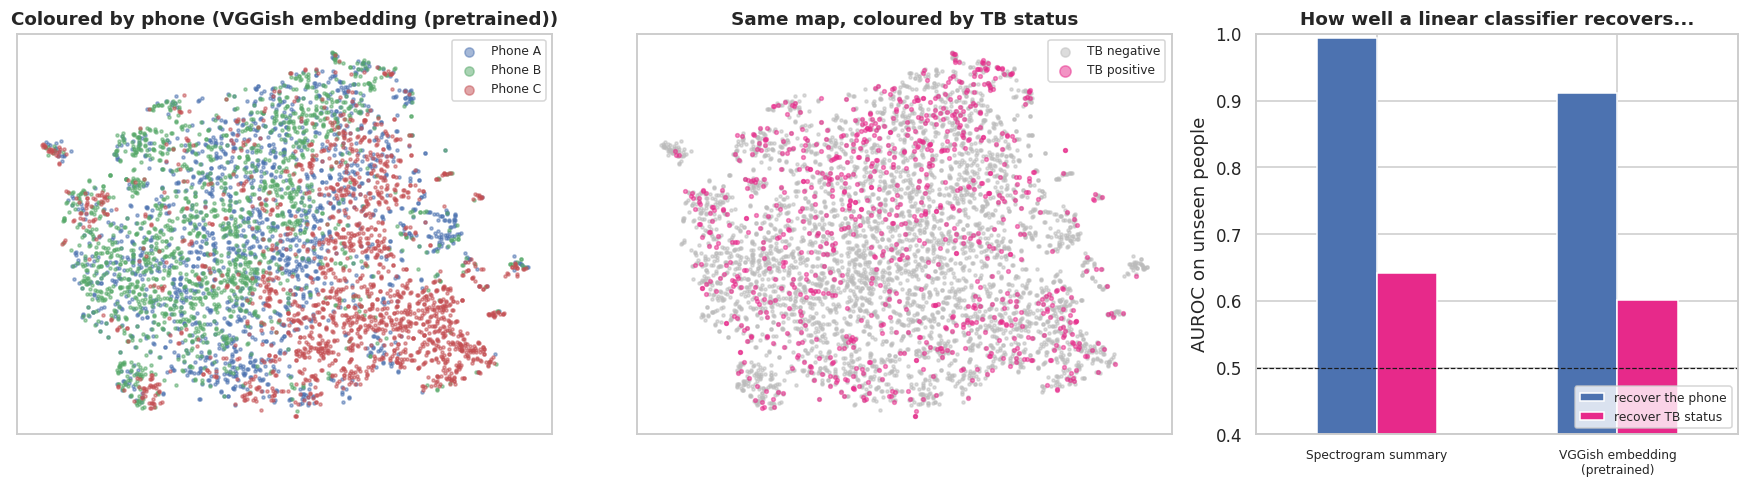

Saved: /kaggle/working/outputs/embedding_space_phone_vs_tb.png and /kaggle/working/outputs/embedding_probe_results.csv


In [5]:
name = list(feature_sets)[-1]
idx = np.arange(len(meta))
if len(idx) > CFG["TSNE_MAX_CLIPS"]:
    idx = np.random.default_rng(CFG["SEED"]).choice(idx, CFG["TSNE_MAX_CLIPS"], replace=False)
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=CFG["SEED"]).fit_transform(
    StandardScaler().fit_transform(feature_sets[name][idx]))
m_dev, m_lab = meta.device.values[idx], meta.label.values[idx]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
pal = dict(zip(PHONES, ["#4C72B0", "#55A868", "#C44E52"]))
for dev in PHONES:
    axes[0].scatter(Z[m_dev == dev, 0], Z[m_dev == dev, 1], s=4, alpha=0.5, color=pal[dev], label=dev)
axes[0].set(title=f"Coloured by phone ({name})", xticks=[], yticks=[]); axes[0].legend(markerscale=3, fontsize=8)
for v, col, lab in [(0, "#BBBBBB", "TB negative"), (1, "#E7298A", "TB positive")]:
    axes[1].scatter(Z[m_lab == v, 0], Z[m_lab == v, 1], s=4 if v == 0 else 6, alpha=0.5, color=col, label=lab)
axes[1].set(title="Same map, coloured by TB status", xticks=[], yticks=[]); axes[1].legend(markerscale=3, fontsize=8)
bars = probe.set_index("features")[["phone: AUROC (chance 0.5)", "TB: AUROC per clip (chance 0.5)"]]
bars.columns = ["recover the phone", "recover TB status"]
bars.plot.bar(ax=axes[2], color=["#4C72B0", "#E7298A"], rot=0)
axes[2].axhline(0.5, color="k", ls="--", lw=0.8); axes[2].legend(fontsize=8, loc="lower right")
axes[2].set(title="How well a linear classifier recovers...", ylabel="AUROC on unseen people", ylim=(0.4, 1.0), xlabel="")
axes[2].set_xticklabels([t.get_text().replace(" (pretrained)", "\n(pretrained)") for t in axes[2].get_xticklabels()], fontsize=8)
plt.tight_layout()
fig.savefig(OUT / "embedding_space_phone_vs_tb.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", OUT / "embedding_space_phone_vs_tb.png", "and", OUT / "embedding_probe_results.csv")

## 5. Site check: is the weak TB signal real, or does it come from the clinic?

**Why.** Kanyama's TB rate (about 21%) is more than twice Chawama's (about 8.5%). If the features reveal *which clinic* recorded a cough, a classifier can score Kanyama coughs higher and look as if it detects TB. The phone cannot play this trick here, because every person was recorded on all three phones, but the clinic can.

**Three checks.**
1. **Can the features recover the site?** (AUROC, chance 0.5.)
2. **What would a pure site shortcut score?** Give every Kanyama person one score and every Chawama person another, and measure the TB AUROC that produces.
3. **Does the TB signal survive inside each site?** Take the same TB predictions as Section 3 and measure AUROC *within* Chawama and *within* Kanyama separately. Comparing only people from the same clinic removes any advantage from knowing the clinic.

**How to read it.** If TB AUROC within each site stays close to the overall value, the TB signal is real. If it falls towards 0.5, the overall value was mostly the clinic. Chawama has few TB-positive people, so its number is noisy.

,features,site: AUROC (chance 0.5),"TB: AUROC, both sites",TB: AUROC from site alone,TB: AUROC within Chawama (10 TB+),TB: AUROC within Kanyama (47 TB+)
0,Spectrogram summary,0.729,0.664,0.599,0.476,0.692
1,VGGish embedding (pretrained),0.591,0.652,0.599,0.572,0.651


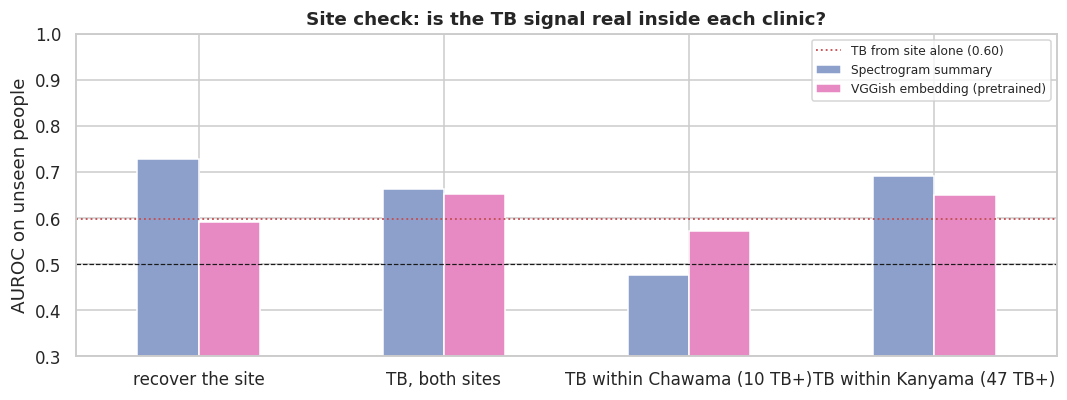

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

def probe_pipe(balanced=False):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced" if balanced else None))

site_rows = []
person = meta.groupby("subject_id").agg(site=("site", "first"), y=("label", "first"))
site_only_auc = roc_auc_score(person.y, (person.site == "Kanyama").astype(float))
for name, F in feature_sets.items():
    site_p = cross_val_predict(probe_pipe(), F, meta.site, cv=cv, groups=groups, method="predict_proba")[:, 1]
    tb_p = cross_val_predict(probe_pipe(True), F, meta.label, cv=cv, groups=groups, method="predict_proba")[:, 1]
    pp = pd.DataFrame({"s": groups, "p": tb_p}).groupby("s").p.median()
    per = person.join(pp)
    row = {"features": name,
           "site: AUROC (chance 0.5)": round(roc_auc_score(meta.site == "Kanyama", site_p), 3),
           "TB: AUROC, both sites": round(roc_auc_score(per.y, per.p), 3),
           "TB: AUROC from site alone": round(site_only_auc, 3)}
    for site_name, g in per.groupby("site"):
        row[f"TB: AUROC within {site_name} ({int(g.y.sum())} TB+)"] = round(roc_auc_score(g.y, g.p), 3)
    site_rows.append(row)
site_check = pd.DataFrame(site_rows)
display(site_check)
site_check.to_csv(OUT / "site_check.csv", index=False)

within_cols = [c for c in site_check.columns if c.startswith("TB: AUROC within")]
plot_df = site_check.set_index("features")[["site: AUROC (chance 0.5)", "TB: AUROC, both sites"] + within_cols]
plot_df.columns = ["recover the site", "TB, both sites"] + [c.replace("TB: AUROC within ", "TB within ") for c in within_cols]
ax = plot_df.T.plot.bar(figsize=(10, 3.8), rot=0, color=["#8DA0CB", "#E78AC3"])
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.axhline(site_only_auc, color="#C44E52", ls=":", lw=1.2, label=f"TB from site alone ({site_only_auc:.2f})")
ax.set(title="Site check: is the TB signal real inside each clinic?", ylabel="AUROC on unseen people", ylim=(0.3, 1.0))
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(OUT / "site_check.png", dpi=200, bbox_inches="tight"); plt.show()

## 6. The same cough on two phones

**Why.** Cough number *k* of a person is the *same physical cough* on every phone, because all three recorded it at once. So we can ask a question no other dataset allows: does changing the **phone** alter a cough's features more than changing the **person**?

**Four kinds of pairs**, compared by how far apart their features are (cosine distance, 0 = identical direction):
1. **Same cough, different phone:** the only thing that differs is the microphone.
2. **Same person, same phone, different cough:** the same person coughing again.
3. **Different people, same phone:** a different person on the same microphone.
4. **Different people, different phones:** nothing shared; the reference for "unrelated".

**How to read it.** If pair type 1 is as far apart as type 3 or further, swapping the phone changes the features as much as swapping the person, which is the device effect in its plainest form.

,0,1
features,Spectrogram summary,VGGish embedding (pretrained)
"same cough, different phone: median",0.645,0.647
"same person & phone, different cough: median",0.198,0.647
"different people, same phone: median",0.626,0.945
"different people, different phones: median",1.175,1.051
same cough on two phones is farther apart than the typical different-person pair (%),51.3,17.4
"same cough, Phone A vs Phone B: median",0.317,0.471
"same cough, Phone A vs Phone C: median",1.005,0.727
"same cough, Phone B vs Phone C: median",0.773,0.753


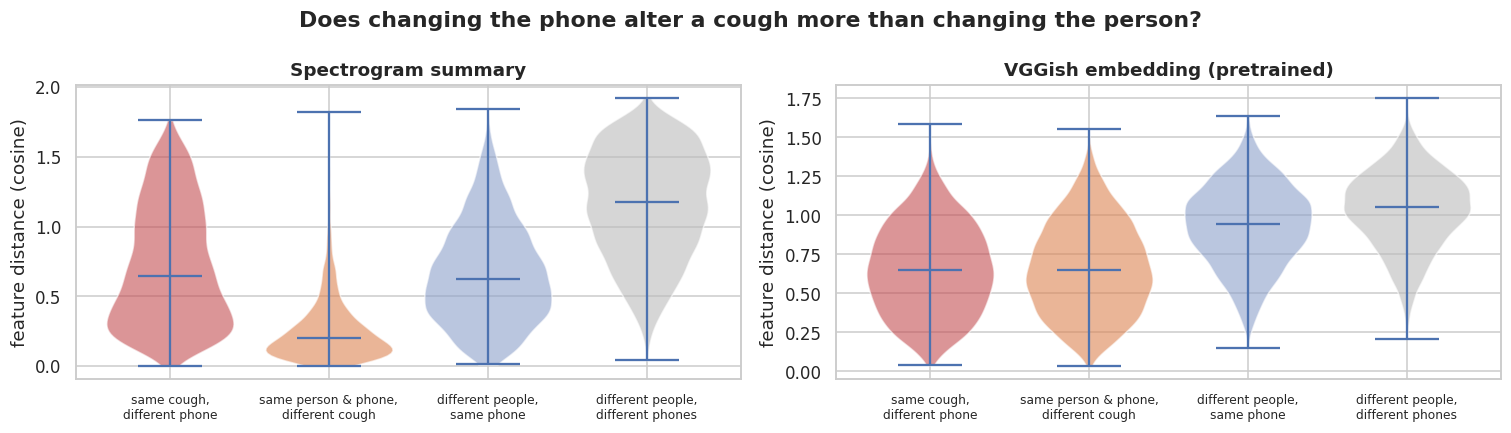

In [7]:
from scipy.spatial.distance import cdist
rng = np.random.default_rng(CFG["SEED"])
m = meta.reset_index(drop=True)
m["cough"] = m.subject_id + "#" + m.clip_idx.astype(str)

def cos_dist(Fz, a, b):
    A, B = Fz[a], Fz[b]
    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1) + 1e-12)

pair_rows, dist_tables = [], {}
for name, F in feature_sets.items():
    Fz = StandardScaler().fit_transform(F)
    same_cough = [(i, j) for _, g in m.groupby("cough") for i, j in itertools.combinations(g.index, 2)]
    sc = np.array(same_cough)
    n = len(sc)
    same_person = [(i, j) for _, g in m.groupby(["subject_id", "device"]) for i, j in itertools.combinations(g.index, 2)]
    sp = np.array(same_person)[rng.choice(len(same_person), min(n, len(same_person)), replace=False)]
    a = rng.integers(0, len(m), 6 * n); b = rng.integers(0, len(m), 6 * n)
    diff_person = m.subject_id.values[a] != m.subject_id.values[b]
    same_dev = m.device.values[a] == m.device.values[b]
    dp_sd = np.c_[a, b][diff_person & same_dev][:n]
    dp_dd = np.c_[a, b][diff_person & ~same_dev][:n]
    groups_d = {"same cough,\ndifferent phone": sc, "same person & phone,\ndifferent cough": sp,
                "different people,\nsame phone": dp_sd, "different people,\ndifferent phones": dp_dd}
    d = {k: cos_dist(Fz, v[:, 0], v[:, 1]) for k, v in groups_d.items()}
    dist_tables[name] = d
    row = {"features": name}
    row.update({k.replace("\n", " ") + ": median": round(float(np.median(v)), 3) for k, v in d.items()})
    ref = np.median(d["different people,\nsame phone"])
    row["same cough on two phones is farther apart than the typical different-person pair (%)"] = round(100 * float((d["same cough,\ndifferent phone"] > ref).mean()), 1)
    devs = m.device.values
    for p1, p2 in itertools.combinations(PHONES, 2):
        mask = ((devs[sc[:, 0]] == p1) & (devs[sc[:, 1]] == p2)) | ((devs[sc[:, 0]] == p2) & (devs[sc[:, 1]] == p1))
        row[f"same cough, {p1} vs {p2}: median"] = round(float(np.median(d["same cough,\ndifferent phone"][mask])), 3)
    pair_rows.append(row)
pairs_summary = pd.DataFrame(pair_rows)
display(pairs_summary.T)
pairs_summary.to_csv(OUT / "same_cough_distances.csv", index=False)

fig, axes = plt.subplots(1, len(dist_tables), figsize=(7 * len(dist_tables), 4), squeeze=False)
cols = ["#C44E52", "#DD8452", "#8DA0CB", "#BBBBBB"]
for ax, (name, d) in zip(axes[0], dist_tables.items()):
    parts = ax.violinplot(list(d.values()), showmedians=True, widths=0.8)
    for body, c in zip(parts["bodies"], cols):
        body.set_facecolor(c); body.set_alpha(0.6)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(list(d.keys()), fontsize=8)
    ax.set(title=name, ylabel="feature distance (cosine)")
fig.suptitle("Does changing the phone alter a cough more than changing the person?", fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "same_cough_distances.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Early test of the main question: TB on a phone the classifier never heard

**Why.** This previews Notebook 02 with a simple linear classifier. For each phone in turn:
* **Seen:** train on all three phones' clips of the training people, test on this phone's clips of the test people.
* **Unseen:** train only on the *other two* phones' clips of the training people, test on this phone's clips of the test people.

The test people and test clips are identical in both conditions, so any difference is caused only by whether the phone was in training. Scaling is learned from training clips only, so the held-out phone never leaks in.

**Two measures per held-out phone.**
* **TB AUROC**, seen versus unseen (per person, median over their clips).
* **Score shift:** the average change in a person's predicted risk between the two conditions, on a 0 to 1 scale. This is a first look at the device-shift measure *D* from our proposal.

,features,held-out phone,people,TB+,"TB AUROC, phone seen","TB AUROC, phone unseen",score shift (mean |seen - unseen|),change in AUROC
0,Spectrogram summary,Phone A,314,55,0.697,0.671,0.064,-0.026
1,Spectrogram summary,Phone B,313,57,0.693,0.696,0.044,0.003
2,Spectrogram summary,Phone C,321,57,0.673,0.620,0.126,-0.053
3,VGGish embedding (pretrained),Phone A,314,55,0.667,0.642,0.043,-0.025
4,VGGish embedding (pretrained),Phone B,313,57,0.655,0.651,0.037,-0.004
5,VGGish embedding (pretrained),Phone C,321,57,0.604,0.575,0.099,-0.029


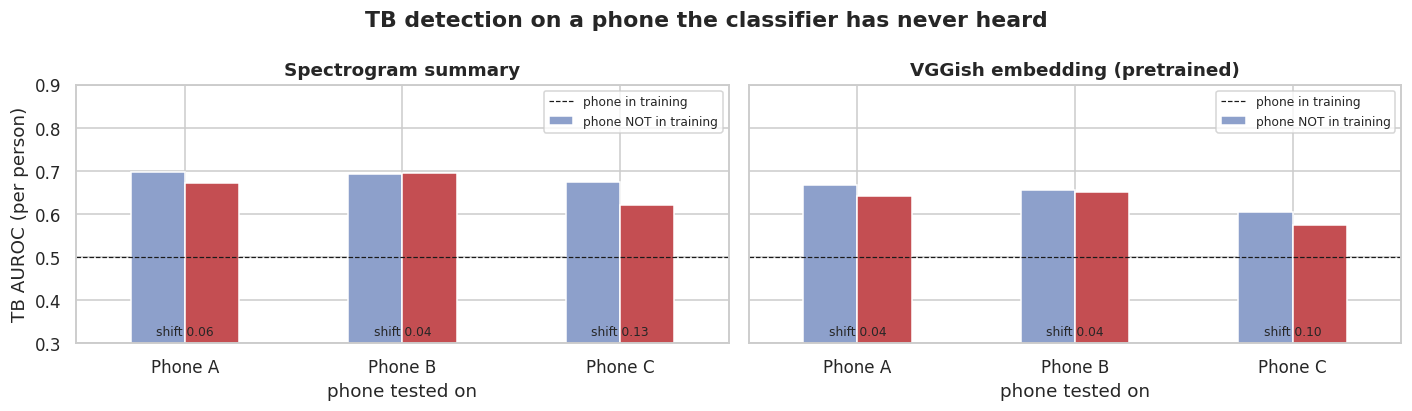

In [8]:
person_ids = person.index.values
person_strata = (person.site + "_" + person.y.astype(str)).values
outer = list(StratifiedKFold(5, shuffle=True, random_state=CFG["SEED"]).split(person_ids, person_strata))
lopo_rows = []
for name, F in feature_sets.items():
    for held in PHONES:
        scores = {"seen": [], "unseen": []}
        for tr_i, te_i in outer:
            tr_p, te_p = set(person_ids[tr_i]), set(person_ids[te_i])
            in_tr, in_te = meta.subject_id.isin(tr_p).values, meta.subject_id.isin(te_p).values
            test = in_te & (meta.device.values == held)
            for cond, train in (("seen", in_tr), ("unseen", in_tr & (meta.device.values != held))):
                mdl = probe_pipe(True).fit(F[train], meta.label.values[train])
                scores[cond].append(pd.DataFrame({"s": groups[test], "p": mdl.predict_proba(F[test])[:, 1]}))
        per = {c: pd.concat(v).groupby("s").p.median() for c, v in scores.items()}
        both = pd.DataFrame(per).join(person.y).dropna()
        lopo_rows.append({"features": name, "held-out phone": held, "people": len(both), "TB+": int(both.y.sum()),
                          "TB AUROC, phone seen": round(roc_auc_score(both.y, both.seen), 3),
                          "TB AUROC, phone unseen": round(roc_auc_score(both.y, both.unseen), 3),
                          "score shift (mean |seen - unseen|)": round(float((both.seen - both.unseen).abs().mean()), 3)})
lopo = pd.DataFrame(lopo_rows)
lopo["change in AUROC"] = (lopo["TB AUROC, phone unseen"] - lopo["TB AUROC, phone seen"]).round(3)
display(lopo)
lopo.to_csv(OUT / "unseen_phone_probe.csv", index=False)

fig, axes = plt.subplots(1, len(feature_sets), figsize=(6.5 * len(feature_sets), 3.8), squeeze=False, sharey=True)
for ax, (name, g) in zip(axes[0], lopo.groupby("features", sort=False)):
    g.set_index("held-out phone")[["TB AUROC, phone seen", "TB AUROC, phone unseen"]].plot.bar(
        ax=ax, rot=0, color=["#8DA0CB", "#C44E52"])
    ax.axhline(0.5, color="k", ls="--", lw=0.8)
    for k, (_, r) in enumerate(g.iterrows()):
        ax.text(k, 0.32, f"shift {r['score shift (mean |seen - unseen|)']:.2f}", ha="center", fontsize=8)
    ax.set(title=name, ylabel="TB AUROC (per person)", xlabel="phone tested on", ylim=(0.3, 0.9))
    ax.legend(["phone in training", "phone NOT in training"], fontsize=8, loc="upper right")
fig.suptitle("TB detection on a phone the classifier has never heard", fontweight="bold")
plt.tight_layout(); plt.savefig(OUT / "unseen_phone_probe.png", dpi=200, bbox_inches="tight"); plt.show()

## What to send back for the report

Everything is saved in `outputs/`:

| Section | Table | Figure |
| --- | --- | --- |
| 3 and 4. Phone versus TB | `embedding_probe_results.csv` | `embedding_space_phone_vs_tb.png` |
| 5. Site check | `site_check.csv` | `site_check.png` |
| 6. Same cough on two phones | `same_cough_distances.csv` | `same_cough_distances.png` |
| 7. Unseen phone | `unseen_phone_probe.csv` | `unseen_phone_probe.png` |

**Reading the result.** If phone AUROC is far above TB AUROC, and the map shows islands by phone but a mixed picture by TB, the features are organised by device more than by disease. That supports Zhang et al.'s finding on our own data, and it is the reason the leave-one-phone-out test matters.